# Compiling RxInfer with Reactant

[Reactant.jl](https://github.com/EnzymeAD/Reactant.jl) compiles Julia functions into [XLA](https://openxla.org/xla) programs for CPUs, GPUs and TPUs. It works by tracing: the function runs once with *traced* arrays, which record every array operation, while everything else (control flow on plain values, dictionaries, dispatch) runs as ordinary Julia at trace time and leaves nothing in the compiled program.

RxInfer's inference is a reactive program: messages flow through subscriptions between the nodes of a factor graph. Under tracing, all of that machinery runs once, and what remains is the arithmetic of the messages. A call to `infer` can therefore compile into one straight-line program.

This example takes one step of a Kalman filter written as an RxInfer model and compiles it. Along the way it shows why the model, written with RxInfer's standard nodes, does not compile yet, and how to convert it into one that does: a distribution, a node and its rules written for traced numbers.

In [1]:
using RxInfer, Reactant, LinearAlgebra, StableRNGs, BenchmarkTools, Plots
import BayesBase

## The model

The hidden state rotates by a fixed angle at every step and is observed with noise:

$$\begin{aligned}
x_t &\sim \mathcal{N}(A x_{t-1}, P), \\
y_t &\sim \mathcal{N}(B x_t, Q).
\end{aligned}$$

One step of filtering takes the belief about the previous state, $\mathcal{N}(m_{t-1}, V_{t-1})$, and one observation, and returns the belief about the current state. Repeated over a stream of observations, each posterior becoming the next prior, it is the Kalman filter. As an RxInfer model:

In [2]:
@model function filter_step(y, m_prev, V_prev, A, B, P, Q)
    x_prev ~ MvNormalMeanCovariance(m_prev, V_prev)
    x ~ MvNormalMeanCovariance(A * x_prev, P)
    y ~ MvNormalMeanCovariance(B * x, Q)
end

function step(y, m_prev, V_prev, A, B, P, Q)
    result = infer(
        model = filter_step(m_prev = m_prev, V_prev = V_prev, A = A, B = B, P = P, Q = Q),
        data = (y = y,),
        returnvars = (x = KeepLast(),),
        disable_inference_error_hint = true,
    )
    posterior = result.posteriors[:x]
    return mean(posterior), cov(posterior)
end

step (generic function with 1 method)

## Data

In [3]:
θ = π / 35
A = [cos(θ) -sin(θ); sin(θ) cos(θ)]
B = diageye(2)
P = diageye(2)
Q = 25.0 * diageye(2)

rng = StableRNG(1234)
n = 300
x = Vector{Vector{Float64}}(undef, n)
y = Vector{Vector{Float64}}(undef, n)
previous = zeros(2)
for t in 1:n
    x[t] = rand(rng, MvNormal(A * previous, P))
    y[t] = rand(rng, MvNormal(B * x[t], Q))
    global previous = x[t]
end

## Filtering with RxInfer

The filter runs `step` once per observation. Every call creates a small factor graph, runs the messages through it and returns the posterior.

In [4]:
function run_filter(step, y, m0, V0, A, B, P, Q)
    m, V = m0, V0
    means, covariances = [], []
    for yt in y
        m, V = step(yt, m, V, A, B, P, Q)
        push!(means, m)
        push!(covariances, V)
    end
    return means, covariances
end

m0, V0 = zeros(2), 100.0 * diageye(2)
means, covariances = run_filter(step, y, m0, V0, A, B, P, Q);

## A first attempt at compiling

`Reactant.to_rarray` moves arrays to Reactant's device, and `@compile` traces a function with them. Tracing `step` as it is fails:

In [5]:
ry = [Reactant.to_rarray(yt) for yt in y]
rm0, rV0, rA, rB, rP, rQ = Reactant.to_rarray.((m0, V0, A, B, P, Q))

compile_error = try
    @compile step(first(ry), rm0, rV0, rA, rB, rP, rQ)
    nothing
catch error
    error
end
compile_error isa MethodError && compile_error.f === MvNormalMeanCovariance || error("Reactant compiles RxInfer's standard nodes now: update this example") # hide
println(first(sprint(showerror, compile_error), 400))

┌ Warning: Reactant doesn't support sampling of UInt128 with the current interpreter. Falling back to native interpreter.
└ @ Reactant /Users/mykola/.julia/packages/Reactant/aBNpn/src/Overlay.jl:167


MethodError: no method matching MvNormalMeanCovariance(::Reactant.TracedRArray{Float64, 1}, ::Reactant.TracedRArray{Float64, 2})
The type `MvNormalMeanCovariance` exists, but no method is defined for this combination of argument types when trying to construct it.

Closest candidates are:
  MvNormalMeanCovariance(::AbstractVector{L}, !Matched::AbstractVector{R}) where {L, R}
   @ ExponentialFamily 


The element of a traced array is a traced number, `Reactant.TracedRNumber{Float64}`, and it is a `Number` but not a `Real`. The distributions RxInfer's nodes compute with, from [ExponentialFamily.jl](https://github.com/ReactiveBayes/ExponentialFamily.jl) and [Distributions.jl](https://github.com/JuliaStats/Distributions.jl), require `Real` parameters, so `MvNormalMeanCovariance` cannot hold a traced mean. Traced numbers that are `Real` are proposed in [EnzymeAD/Reactant.jl#2170](https://github.com/EnzymeAD/Reactant.jl/pull/2170); why they are not `Real` today is discussed in [EnzymeAD/Reactant.jl#1570](https://github.com/EnzymeAD/Reactant.jl/issues/1570).

Until then, a model compiles when every distribution its messages hold accepts any number. RxInfer does not need its own distributions for that: a rule can return any type, as long as the engine knows how to multiply it with the other messages. The rest of this example converts the model in three steps.

## Converting the model

### 1. Messages for any number

The belief about a state is a Gaussian with a mean and a covariance. An observation sends a likelihood message: as a function of the state $x$, it is proportional to $\exp[-\tfrac{1}{2}(y - Bx)^\top Q^{-1}(y - Bx)]$. We keep this message as the observation $y$, the map $B$ and the noise covariance $Q$, postponing the linear algebra until it is multiplied with the predicted belief.

The likelihood need not be a normalized distribution over $x$, so this representation also works when $B$ is rectangular and only part of the state is observed.

Neither type bounds its number type, only its shape.

In [6]:
# A multivariate normal by its mean `μ` and covariance `Σ`, of any number type
struct TracedMvNormal{M <: AbstractVector, V <: AbstractMatrix}
    μ::M
    Σ::V
end

# The likelihood N(y | B*x, Q), kept as data until combined with a state belief
struct ObservationLikelihood{Y <: AbstractVector, M <: AbstractMatrix, V <: AbstractMatrix}
    y::Y
    B::M
    Q::V
end

BayesBase.mean(d::TracedMvNormal) = d.μ
BayesBase.cov(d::TracedMvNormal) = d.Σ

The posterior is the product of the predicted belief $\mathcal{N}(\mu, \Sigma)$ and the observation's likelihood. We compute this product in the Kalman innovation form:

$$\begin{aligned}
T &= B\Sigma, & S &= T B^\top + Q, \\
K &= (S^{-1}T)^\top, & \mu' &= \mu + K(y - B\mu), \\
&& \Sigma' &= \Sigma - KT.
\end{aligned}$$

Here $S$ is the covariance of the observation residual. Since the covariances are symmetric, solving $SZ = T$ and transposing $Z$ gives the Kalman gain $K$. Positive-definite observation noise makes $S$ positive definite even for rectangular $B$.

One LU factorisation and one matrix solve give $K$, which is reused for both the mean and the covariance. No inverse is formed, and no observation terms are precomputed outside inference. On a CPU, Reactant's LU factorisation calls LAPACK, while its Cholesky factorisation is much slower ([EnzymeAD/Reactant.jl#3411](https://github.com/EnzymeAD/Reactant.jl/issues/3411)), so the rules here use LU.

The helper `blocked_lu_solve(S, T)` computes the same solution as `lu(S) \ T`. After applying the LU row permutation to `T`, it performs forward and backward substitution in row blocks. Each block uses a small triangular solve, while updates from other blocks use matrix multiplication. This reduces the cost of Reactant's large triangular solves on the CPU in this example.

`blocksize = 32` is a CPU tuning choice, not a restriction on the matrix dimensions: the final block can be smaller, and the right-hand side can be rectangular. The matrix sizes and block size are known during tracing, so the block loops are unrolled into the compiled program. Both ordinary Julia arrays and traced arrays use the same helper.

`default_prod_rule` tells the engine that the product of the two has a closed form, `ClosedProd`, and `prod` computes it.

In [7]:
# Julia's LU and Reactant's traced LU expose the row permutation differently.
lu_permutation(F::LinearAlgebra.LU) = F.p
lu_permutation(F) = F.perm

function blocked_lu_solve(S, T; blocksize = 32)
    @assert blocksize > 0
    F = lu(S)
    factors = F.factors
    X = T[Int64.(lu_permutation(F)), :]
    n = size(S, 1)

    # Forward substitution: solve L * Y = T[permutation, :].
    for firstrow in 1:blocksize:n
        rows = firstrow:min(firstrow + blocksize - 1, n)
        rhs = X[rows, :]
        if firstrow > 1
            previous = 1:(firstrow - 1)
            rhs = rhs - factors[rows, previous] * X[previous, :]
        end
        X[rows, :] = UnitLowerTriangular(factors[rows, rows]) \ rhs
    end

    # Backward substitution: overwrite Y with the solution of U * X = Y.
    lastblock = 1 + fld(n - 1, blocksize) * blocksize
    for firstrow in lastblock:(-blocksize):1
        lastrow = min(firstrow + blocksize - 1, n)
        rows = firstrow:lastrow
        rhs = X[rows, :]
        if lastrow < n
            following = (lastrow + 1):n
            rhs = rhs - factors[rows, following] * X[following, :]
        end
        X[rows, :] = UpperTriangular(factors[rows, rows]) \ rhs
    end
    return X
end

BayesBase.default_prod_rule(::Type{<:TracedMvNormal}, ::Type{<:ObservationLikelihood}) = BayesBase.ClosedProd()
BayesBase.default_prod_rule(::Type{<:ObservationLikelihood}, ::Type{<:TracedMvNormal}) = BayesBase.ClosedProd()

function BayesBase.prod(::BayesBase.ClosedProd, prior::TracedMvNormal, likelihood::ObservationLikelihood)
    B, Q, y = likelihood.B, likelihood.Q, likelihood.y
    T = B * prior.Σ
    S = T * B' + Q
    K = blocked_lu_solve(S, T; blocksize = 32)'
    μpost = prior.μ + K * (y - B * prior.μ)
    Σpost = prior.Σ - K * T
    return TracedMvNormal(μpost, Σpost)
end

BayesBase.prod(strategy::BayesBase.ClosedProd, likelihood::ObservationLikelihood, prior::TracedMvNormal) =
    BayesBase.prod(strategy, prior, likelihood)

### 2. The nodes

The prior is a node of its own, `x_prev ~ TracedMvNormal(m_prev, V_prev)`, with one rule: the message towards `out` is the distribution itself. RxInfer gives a node its constants as marginals, `q[:μ]` and `q[:Σ]`, point masses holding the traced arrays.

In [8]:
@define_factor_node(node = TracedMvNormal, type = Stochastic, interfaces = [:out, :μ, :Σ])

@define_message_update_rule(
    node = TracedMvNormal,
    target = :out,
    args = (q[:μ]::PointMass, q[:Σ]::PointMass),
    body = (args) -> TracedMvNormal(mean(args.q[:μ]), mean(args.q[:Σ])),
)

The transition and the observation have the same form, a linear map of one variable with Gaussian noise. A single node, `out ~ LinearGaussian(in, A, Σ)`, stands for $\mathcal{N}(\mathrm{out} \mid A \cdot \mathrm{in}, \Sigma)$, and replaces both the multiplication node and the normal node of the original model. It needs two rules:

- towards `out`, from a belief about `in`: the prediction, $\mathcal{N}(A \mu, A \Sigma A^\top + \Sigma_{\mathrm{noise}})$;
- towards `in`, from an observed `out`: `ObservationLikelihood(y, A, Σ)`, which carries the observation, map and noise covariance. The product rule above performs the solve when this message meets the predicted belief.

In [9]:
struct LinearGaussian end

@define_factor_node(node = LinearGaussian, type = Stochastic, interfaces = [:out, :in, :A, :Σ])

@define_message_update_rule(
    node = LinearGaussian,
    target = :out,
    args = (m[:in]::TracedMvNormal, q[:A]::PointMass, q[:Σ]::PointMass),
    body = (args) -> begin
        A, belief = mean(args.q[:A]), args.m[:in]
        TracedMvNormal(A * belief.μ, A * belief.Σ * A' + mean(args.q[:Σ]))
    end,
)

@define_message_update_rule(
    node = LinearGaussian,
    target = :in,
    args = (q[:out]::PointMass, q[:A]::PointMass, q[:Σ]::PointMass),
    body = (args) -> ObservationLikelihood(mean(args.q[:out]), mean(args.q[:A]), mean(args.q[:Σ])),
)

These are exactly the rules filtering needs, and no more. A smoother would also send messages backwards through the transition, towards `in` from a belief about `out`; that rule is left out, and `returnvars = (x = KeepLast(),)` asks only for the posterior of `x`, so the engine never needs it. Without it, inference stops with an error that names the missing rule.

### 3. The model

The model reads as before, with the new nodes:

In [10]:
@model function traced_filter_step(y, m_prev, V_prev, A, B, P, Q)
    x_prev ~ TracedMvNormal(m_prev, V_prev)
    x ~ LinearGaussian(x_prev, A, P)
    y ~ LinearGaussian(x, B, Q)
end

function traced_step(y, m_prev, V_prev, A, B, P, Q)
    result = infer(
        model = traced_filter_step(m_prev = m_prev, V_prev = V_prev, A = A, B = B, P = P, Q = Q),
        data = (y = y,),
        returnvars = (x = KeepLast(),),
    )
    posterior = result.posteriors[:x]
    return mean(posterior), cov(posterior)
end

traced_step (generic function with 1 method)

The prior is written inside the model, `x_prev ~ TracedMvNormal(m_prev, V_prev)`, rather than passed in as a distribution: under tracing, a reduction over plain values inside a trace can give a traced result ([EnzymeAD/Reactant.jl#3410](https://github.com/EnzymeAD/Reactant.jl/issues/3410)), which trips the model's check of a distribution argument.

On ordinary arrays, the new model is plain RxInfer and gives the same posteriors as the original:

In [11]:
traced_means, traced_covariances = run_filter(traced_step, y, m0, V0, A, B, P, Q)
maximum(maximum(abs, a - b) for (a, b) in zip(means, traced_means))

1.4210854715202004e-14

## Compiling one step

`@compile` traces `traced_step` once and returns the compiled program. It runs for every observation, and the posterior it returns, already on the device, is the next step's prior.

In [12]:
compile_time = @elapsed compiled_step = @compile sync = true traced_step(first(ry), rm0, rV0, rA, rB, rP, rQ)
println("compiled in ", round(compile_time, digits = 1), " s")

compiled_means, compiled_covariances = run_filter(compiled_step, ry, rm0, rV0, rA, rB, rP, rQ);

compiled in 30.7 s


The compiled filter computes the same posteriors as RxInfer with the standard nodes:

In [13]:
difference = maximum(zip(means, compiled_means, covariances, compiled_covariances)) do (m, rm, V, rV)
    return max(maximum(abs, m - Array(rm)), maximum(abs, V - Array(rV)))
end
println("largest difference: ", difference)

largest difference: 1.4210854715202004e-14


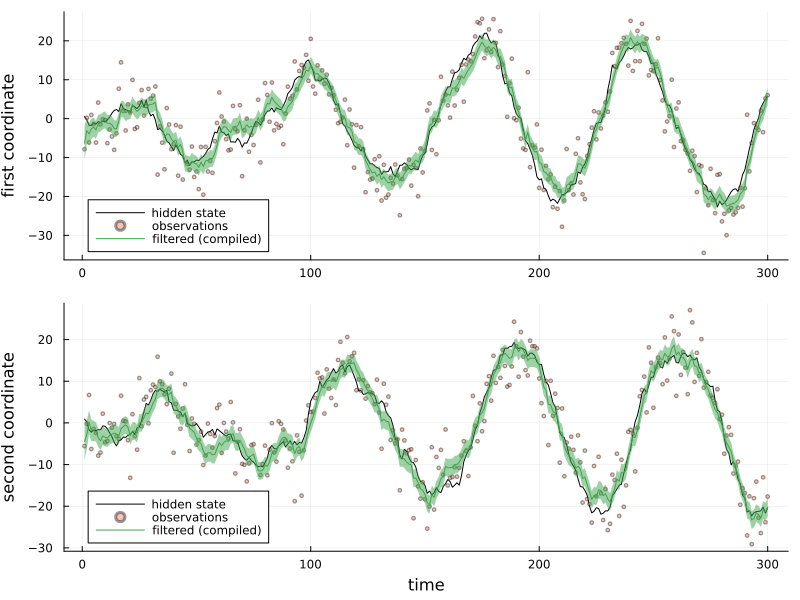

In [14]:
filtered = Array.(compiled_means)
stds = [sqrt.(diag(Array(V))) for V in compiled_covariances]
p1 = plot(getindex.(x, 1), label = "hidden state", color = :black, ylabel = "first coordinate")
scatter!(p1, getindex.(y, 1), label = "observations", markersize = 2, alpha = 0.4)
plot!(p1, getindex.(filtered, 1), ribbon = getindex.(stds, 1), label = "filtered (compiled)")
p2 = plot(getindex.(x, 2), label = "hidden state", color = :black, ylabel = "second coordinate", xlabel = "time")
scatter!(p2, getindex.(y, 2), label = "observations", markersize = 2, alpha = 0.4)
plot!(p2, getindex.(filtered, 2), ribbon = getindex.(stds, 2), label = "filtered (compiled)")
plot(p1, p2, layout = (2, 1), size = (800, 600), legend = :bottomleft)

## What the compiled program contains

The traced program holds only the arithmetic of the messages: the graph, the subscriptions and the rule lookup ran once, at trace time.

In [15]:
hlo = string(@code_hlo traced_step(first(ry), rm0, rV0, rA, rB, rP, rQ))
println(length(collect(eachmatch(r"stablehlo\.\w+", hlo))), " StableHLO operations")

50 StableHLO operations


## Timings

We compare three paths: standard RxInfer (`step`), the custom message rules running in native Julia (`traced_step` on ordinary arrays), and those same custom rules compiled with Reactant. Comparing the two custom-rule paths shows the effect of compilation; comparing standard RxInfer with the compiled path includes the effect of changing the message rules as well.

Both native paths build a factor graph and propagate its messages on every call; the compiled path runs only the numerical operations. All three receive `A`, `B`, `P` and `Q` on every call, and all observation-update arithmetic remains inside the timed step.

In [16]:
plain_trial = @benchmark step($(y[1]), $m0, $V0, $A, $B, $P, $Q)
traced_trial = @benchmark traced_step($(y[1]), $m0, $V0, $A, $B, $P, $Q)
compiled_trial = @benchmark $compiled_step($(ry[1]), $rm0, $rV0, $rA, $rB, $rP, $rQ)
for (name, trial) in (("RxInfer (standard)", plain_trial), ("custom rules (native)", traced_trial), ("custom rules (Reactant)", compiled_trial))
    estimate = median(trial)
    println(rpad(name, 26), BenchmarkTools.prettytime(estimate.time), " per step, ", estimate.allocs, " allocations")
end
println("speed-up vs standard RxInfer: ", round(median(plain_trial).time / median(compiled_trial).time, digits = 1), "×")
println("speed-up from compiling custom rules: ", round(median(traced_trial).time / median(compiled_trial).time, digits = 1), "×")

RxInfer (standard)        138.916 μs per step, 2377 allocations
custom rules (native)     94.792 μs per step, 1628 allocations
custom rules (Reactant)   5.006 μs per step, 12 allocations
speed-up vs standard RxInfer: 27.7×
speed-up from compiling custom rules: 18.9×


### Larger states

The same step for states of more dimensions: the rotation becomes a random orthogonal matrix, and every dimension is observed. For small states, graph construction and message routing can dominate native runtime; at larger dimensions, matrix operations become increasingly important. The custom native and compiled curves use the same message rules and blocked solver, so their difference shows whether Reactant improves their runtime. Each size is a new program, compiled once.

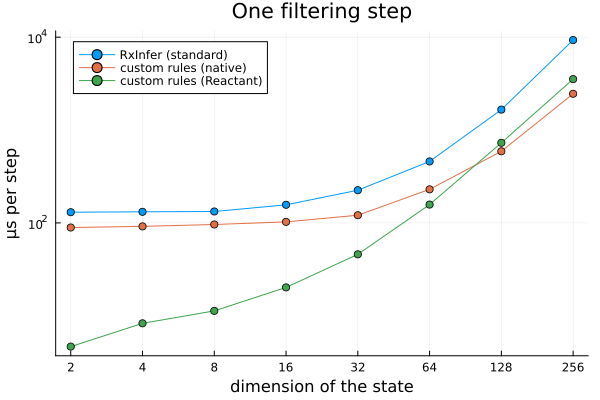

In [18]:
function random_problem(d; rng = StableRNG(d))
    A = Matrix(qr(randn(rng, d, d)).Q)
    B, P, Q = diageye(d), diageye(d), 25.0 * diageye(d)
    y = rand(rng, MvNormal(A * randn(rng, d), Q))
    return y, zeros(d), 100.0 * diageye(d), A, B, P, Q
end

dimensions = [2, 4, 8, 16, 32, 64, 128, 256]

plain_times, traced_times, compiled_times = Float64[], Float64[], Float64[]

options = Reactant.CompileOptions(
    sync = true,
)

for d in dimensions
    args = random_problem(d)
    rargs = Reactant.to_rarray.(args)
    compiled =  @compile compile_options = options traced_step(rargs...)
    reference = step(args...)
    traced = traced_step(args...)
    computed = compiled(rargs...)
    @assert all(maximum(abs, a - b) < 1e-8 for (a, b) in zip(reference, traced))
    @assert all(maximum(abs, a - Array(b)) < 1e-8 for (a, b) in zip(reference, computed))
    push!(plain_times, @belapsed step($(args)...))
    push!(traced_times, @belapsed traced_step($(args)...))
    push!(compiled_times, @belapsed $compiled($(rargs)...))
end

plot(
    dimensions, 1e6 .* [plain_times traced_times compiled_times],
    label = ["RxInfer (standard)" "custom rules (native)" "custom rules (Reactant)"], marker = :circle, xscale = :log2, yscale = :log10,
    xticks = (dimensions, string.(dimensions)), xlabel = "dimension of the state", ylabel = "μs per step",
    title = "One filtering step", legend = :topleft,
)

## The cost of compiling

Compiling takes a while: Reactant traces the whole engine and XLA optimises the result. It pays off when the same program runs many times, as a filtering step does over a long or endless stream of observations. The program is fixed for the shapes it was compiled with, so a model of another size needs its own compilation.

That is why this example compiles one step and loops it. `@compile` can also trace a call to `infer` on a whole state-space model, but the graph is then unrolled into the program: every observation adds its own copy of the step, and both the program and its compile time grow with the length of the data. Compiling one step keeps the program small and its size independent of the number of observations.

The same program also runs on a GPU, with `Reactant.set_default_backend("gpu")` on a machine with an NVIDIA or AMD GPU; the larger the state, the more a GPU has to work with.